# TRAs in mTECII, mTECIII and the mimetic TECs — protein-coding genes only, tau >= 0.8


* **What is filtered.** The gene universe - the TRAs *and* the non-TRA background they are compared
  against - is restricted to protein-coding genes. Filtering only the TRA list would leave lncRNAs and
  pseudogenes in the background and bias every odds ratio.
* **How biotype is assigned.** Through the atlas's own Ensembl `gene_id`, not the symbol: each
  var_name is mapped to its GENCODE gene record (`gene_type == 'protein_coding'`) in the 10x GRCh38
  reference the atlas matches (`_builders/build_gene_biotypes.py`, output
  `General_analysis/data/tra_analysis/gene_biotypes/atlas_v6_gene_biotypes.csv`).
* **TRA definition:** a TRA is `tissue_tau >= 0.8` in GTEx; the universe is genes DESeq2
  tested (`padj` not NaN) that reach >= 1 TPM in their best GTEx tissue; odds ratios are reported raw,
  expression-matched and by permutation.


In [1]:
import os
import sys
from datetime import datetime
today = datetime.today().strftime('%Y-%m-%d')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle as pkl

%matplotlib inline

repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment'
sys.path.insert(1, repo_path)
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'
pd.set_option('display.max_column', None)
pd.options.display.max_rows = 100


In [2]:
# Paths
plot_path = os.path.join(repo_path, 'plots', 'tra')
results_path = os.path.join(repo_path, 'results', 'tra')
os.makedirs(plot_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data'

# Nature-spec formatting: Arial + thyAgeing.mplstyle (7 pt, 0.5 pt lines, mm figure widths)
from matplotlib import font_manager
font_manager.fontManager.addfont('/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf')
plt.style.use('/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')

from utils import get_latest_version
from anno_levels import get_ct_levels, get_ct_palette
from plotting.colors import thyAgeing_colors, thyAgeing_greys
import tra_enrichment as tra


## Palettes in use


In [3]:
# Cell type colours: the curated TEC taa_l4 palette
tec_palette = get_ct_palette(level='taa_l4', taa_l1='TEC')

# Change classes: the atlas teal / grey / orange, straight from tra_enrichment
print('change classes:', tra.CHANGE_COLORS)
print('TRA / non-TRA :', tra.TRA_COLORS)
print('tissue ramp   :', [thyAgeing_colors[c] for c in tra.TISSUE_PALETTE_ORDER])
tec_palette


change classes: {'sign_dw': '#18868F', 'non_sign': '#969696', 'sign_up': '#FE6100'}
TRA / non-TRA : {True: '#785EF0', False: '#cccccc'}
tissue ramp   : ['#648FFF', '#FE6100', '#18868F', '#DC267F', '#FFB000', '#785EF0', '#82CD29', '#C169E8', '#738B79', '#124420']


{'cTECIII': '#6165ef',
 'cTECII': '#ba4500',
 'cTECI': '#00009a',
 'mcTEC': '#eb5dae',
 'mTECI': '#fbc600',
 'mTECII': '#790061',
 'mTECIII': '#20d2ff',
 'mTECI-trans': '#004100',
 'TEC-myo': '#00c28a',
 'TEC-neuro': '#04796d',
 'TEC-cilliated': '#b22059',
 'TEC-iono': '#5d049a',
 'TEC-tuft': '#ff6169',
 'TEC-EMT': '#b235ae'}

## Load the age-DE results and the GTEx tissue-specificity table


In [4]:
def load_de(level, contrast_file, contrast_name):
    with open(f'{general_data_path}/analyses/dea/thyAgeing_dea_{level}_{contrast_file}_ageEffect.pkl', 'rb') as f:
        d = pkl.load(f)
    return tra.flatten_de_dict(d, contrast=contrast_name, col_cell_type=level)

de_l3 = load_de('taa_l3', 'adult_vs_infant', 'adult-vs-infant')
de_l4 = load_de('taa_l4', 'adult_vs_infant', 'adult-vs-infant')
gtex = tra.load_gtex_stats()
print(de_l3.shape, de_l4.shape)


GTEx stats: 54592 unique gene symbols (1608 duplicate rows collapsed with dedup="max_expr")
(772906, 11) (1084147, 11)


In [5]:
# Protein-coding genes, annotated through the atlas Ensembl gene_id
biotypes = tra.load_gene_biotypes()
pc_genes = tra.load_protein_coding_genes()
biotypes['gene_type'].value_counts().head(10)


protein-coding genes: 19,101 of 35,530 atlas genes (GRCh38-2020-A: 35,530)


gene_type
protein_coding     19101
lncRNA             15884
IG_V_gene            144
IG_V_pseudogene      143
TR_V_gene            106
TR_J_gene             77
TR_V_pseudogene       32
IG_C_gene             14
IG_J_gene             11
IG_C_pseudogene        9
Name: count, dtype: int64

## The focus populations

The mimetic subsets are read from the curated annotation rather than hard-coded, so the notebook
follows the annotation if it changes. `TEC-tuft` is annotated but was not tested by DESeq2 (too few
cells or donors), so it drops out here.


In [6]:
anno = pd.read_excel(get_latest_version(dir=f'{general_data_path}/curated',
                                        file_prefix='thyAgeing_full_curatedAnno_'))
mim_l4_all = anno.loc[anno['taa_l3'] == 'TEC-mim', 'taa_l4'].dropna().unique().tolist()
print('mimetic subsets at taa_l4 (annotation):', mim_l4_all)

tested_l3 = set(de_l3['cell_type'])
tested_l4 = set(de_l4['cell_type'])

FOCUS_L3 = [c for c in ['mTECII', 'mTECIII'] if c in tested_l3]
FOCUS_MIM = [c for c in mim_l4_all if c in tested_l4]
print('taa_l3 focus  :', FOCUS_L3)
print('mimetic tested:', FOCUS_MIM)
print('not tested    :', [c for c in mim_l4_all if c not in tested_l4])


Latest file: thyAgeing_full_curatedAnno_v12_2025-09-02_levels.xlsx


mimetic subsets at taa_l4 (annotation): ['mTECI-trans', 'TEC-myo', 'TEC-neuro', 'TEC-cilliated', 'TEC-iono', 'TEC-tuft']
taa_l3 focus  : ['mTECII', 'mTECIII']
mimetic tested: ['mTECI-trans', 'TEC-myo', 'TEC-neuro', 'TEC-cilliated', 'TEC-iono']
not tested    : ['TEC-tuft']


In [7]:
TAU = 0.8   # GTEx tissue-specificity cut-off for a TRA (the original 04f used 0.85)

# TRA tables on the protein-coding universe. mTECII / mTECIII carry the same label at taa_l4, so a
# single taa_l4 table also supports the combined figures - the assertion confirms the cells match.
tra_l3 = tra.build_tra_table(de_l3, gtex=gtex, cell_types=FOCUS_L3, gene_universe=pc_genes, tau=TAU)
tra_mim = tra.build_tra_table(de_l4, gtex=gtex, cell_types=FOCUS_MIM, gene_universe=pc_genes, tau=TAU)

FOCUS_ALL = FOCUS_L3 + FOCUS_MIM
tra_all = tra.build_tra_table(de_l4, gtex=gtex, cell_types=FOCUS_ALL, gene_universe=pc_genes, tau=TAU)

# the same populations without the filter (as in 04d), for section 0
tra_all_nofilter = tra.build_tra_table(de_l4, gtex=gtex, cell_types=FOCUS_ALL, tau=TAU, verbose=False)

for ct in FOCUS_L3:
    n3 = (tra_l3['cell_type'].astype(str) == ct).sum()
    n4 = (tra_all['cell_type'].astype(str) == ct).sum()
    assert n3 == n4, f'{ct}: taa_l3 and taa_l4 tables differ ({n3} vs {n4})'
print('mTECII / mTECIII are identical at taa_l3 and taa_l4 - combined figures use the taa_l4 table')


universe: 21,320 of 41,513 (cell type, gene) rows kept
  - not in GTEx          : 6,653
  - max_expr < 0.693     : 987
  - padj is NaN          : 11,797
  - outside gene universe: 756
  TRAs (tau >= 0.8): 1,406 (6.6% of the universe; 1,071 distinct genes)


universe: 48,462 of 79,771 (cell type, gene) rows kept
  - not in GTEx          : 8,838
  - max_expr < 0.693     : 763
  - padj is NaN          : 20,321
  - outside gene universe: 1,387
  TRAs (tau >= 0.8): 2,106 (4.3% of the universe; 1,045 distinct genes)


universe: 69,782 of 121,284 (cell type, gene) rows kept
  - not in GTEx          : 15,491
  - max_expr < 0.693     : 1,750
  - padj is NaN          : 32,118
  - outside gene universe: 2,143
  TRAs (tau >= 0.8): 3,512 (5.0% of the universe; 1,619 distinct genes)


mTECII / mTECIII are identical at taa_l3 and taa_l4 - combined figures use the taa_l4 table


## 0. What the protein-coding filter changes

First the biotypes of the genes that the unfiltered analysis called TRAs, then the significant
TRAs the filter removes, then the enrichment before and after.


In [8]:
bt = biotypes.drop_duplicates('gene_name').set_index('gene_name')['gene_type']
u = (tra_all_nofilter.drop_duplicates('gene_name')
     .assign(gene_type=lambda x: x['gene_name'].map(bt).fillna('not_annotated')))
biotype_tab = pd.crosstab(u['gene_type'], u['isTRA'].map({True: 'TRA', False: 'non-TRA'}))
biotype_tab['% TRA'] = 100 * biotype_tab['TRA'] / biotype_tab.sum(axis=1)
biotype_tab = biotype_tab.sort_values('TRA', ascending=False)
n_tra = int(u['isTRA'].sum())
n_nc = int((u['isTRA'] & (u['gene_type'] != 'protein_coding')).sum())
print(f'unfiltered universe of these populations: {len(u):,} distinct genes, {n_tra:,} TRAs; '
      f'{n_nc:,} of the TRAs ({100 * n_nc / n_tra:.1f}%) are not protein-coding')
biotype_tab.round(1)


unfiltered universe of these populations: 15,148 distinct genes, 1,800 TRAs; 181 of the TRAs (10.1%) are not protein-coding


isTRA,TRA,non-TRA,% TRA
gene_type,,,
protein_coding,1619,12788,11.2
lncRNA,166,539,23.5
TR_V_gene,15,0,100.0
IG_V_gene,0,8,0.0
IG_C_pseudogene,0,1,0.0
IG_C_gene,0,8,0.0
TR_C_gene,0,4,0.0


In [9]:
# Significant TRAs (down or up) that the filter removes, per population
nf = tra_all_nofilter
removed = nf[nf['isTRA'] & nf['change'].astype(str).isin(['sign_dw', 'sign_up']) &
             ~nf['gene_name'].isin(pc_genes)].copy()
removed['gene_type'] = removed['gene_name'].map(bt).fillna('not_annotated')
removed_tab = (removed.groupby(['cell_type', 'change'], observed=True)
                      .agg(n_removed=('gene_name', 'size'),
                           genes=('gene_name', lambda s: ', '.join(sorted(s))))
                      .reset_index())
removed_tab


,cell_type,change,n_removed,genes
0,mTECII,sign_dw,2,"AFAP1-AS1, PTPRG-AS1"
1,mTECIII,sign_dw,10,"DLX6-AS1, ESRG, FOXD3-AS1, LINC00504, LINC0120..."
2,mTECIII,sign_up,6,"AC006460.2, LINC00632, LINC01551, LINC01644, L..."
3,mTECI-trans,sign_dw,1,EGOT
4,mTECI-trans,sign_up,1,LINC01644
5,TEC-myo,sign_dw,3,"AC098617.1, LINC01405, PTENP1-AS"
6,TEC-myo,sign_up,2,"AC011239.1, LINC01644"


,cell_type,n_focal_all_genes,frac_tra_focal_all_genes,frac_tra_ref_all_genes,OR_matched_all_genes,padj_matched_all_genes,stars_matched_all_genes,n_focal_protein_coding,frac_tra_focal_protein_coding,frac_tra_ref_protein_coding,OR_matched_protein_coding,padj_matched_protein_coding,stars_matched_protein_coding
0,mTECII,49,28.571,5.226,7.909,0.000,***,45,26.667,5.072,7.409,0.000,***
1,mTECIII,501,23.154,7.489,6.257,0.000,***,480,22.083,6.910,6.295,0.000,***
2,mTECI-trans,176,13.636,4.464,4.523,0.000,***,170,13.529,4.268,4.791,0.000,***
3,TEC-myo,413,14.044,4.181,5.359,0.000,***,395,13.924,3.875,5.470,0.000,***
4,TEC-neuro,65,6.154,5.809,1.556,0.382,ns,65,6.154,5.600,1.598,0.353,ns
5,TEC-cilliated,37,16.216,4.217,4.378,0.000,***,37,16.216,4.120,4.334,0.001,***
6,TEC-iono,12,16.667,1.462,14.081,0.000,***,10,20.000,1.377,17.597,0.000,***


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_forest_filter_comparison_mTEC23_TECmim_adult_vs_infant_2026-09-15.pdf


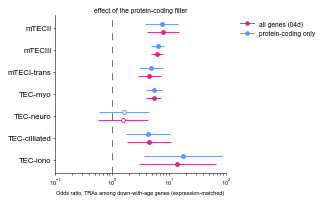

In [10]:
# Down vs no change, before and after the filter
s_nf = tra.tra_summary(tra_all_nofilter, comparison='dw_vs_ns')
s_pc = tra.tra_summary(tra_all, comparison='dw_vs_ns')
keep = ['cell_type', 'n_focal', 'frac_tra_focal', 'frac_tra_ref', 'OR_matched', 'padj_matched',
        'stars_matched']
comparison = (s_nf[keep].assign(cell_type=lambda x: x['cell_type'].astype(str))
              .merge(s_pc[keep].assign(cell_type=lambda x: x['cell_type'].astype(str)),
                     on='cell_type', suffixes=('_all_genes', '_protein_coding')))
for c in [c for c in comparison.columns if c.startswith('frac_')]:
    comparison[c] = 100 * comparison[c]
display(comparison.round(3))

_ = tra.plot_or_forest(
    {'all genes (04d)': tra.cmh_tra(tra_all_nofilter, comparison='dw_vs_ns'),
     'protein-coding only': tra.cmh_tra(tra_all, comparison='dw_vs_ns')},
    cell_types=FOCUS_ALL, annotate_p=False,
    xlabel='Odds ratio, TRAs among down-with-age genes (expression-matched)',
    title='effect of the protein-coding filter',
    save=f'{plot_path}/tra_pc_tau0.8_forest_filter_comparison_mTEC23_TECmim_adult_vs_infant_{today}.pdf')


## 1. Stacked bar plots

TRA vs non-TRA within the genes that go down, do not change, and go up with age. Stars are the
expression-matched test (down vs no change); the number inside each bar is how many genes it holds.


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_stacked_mTEC23_taa_l3_adult_vs_infant_2026-09-15.pdf


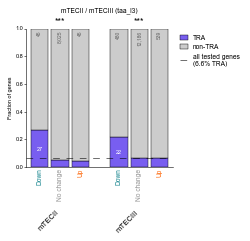

In [11]:
sum_l3 = tra.tra_summary(tra_l3, comparison='dw_vs_ns')
_ = tra.plot_tra_stacked(
    tra_l3, cell_types=FOCUS_L3, stats=sum_l3,
    figsize=tra.calc_figsize(width=60, height=55, margin=0),
    title='mTECII / mTECIII (taa_l3)',
    save=f'{plot_path}/tra_pc_tau0.8_stacked_mTEC23_taa_l3_adult_vs_infant_{today}.pdf')


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_stacked_TECmim_taa_l4_adult_vs_infant_2026-09-15.pdf


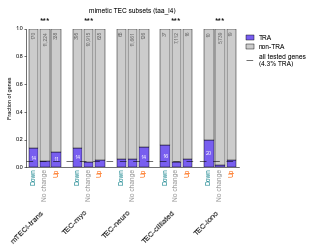

In [12]:
sum_mim = tra.tra_summary(tra_mim, comparison='dw_vs_ns')
_ = tra.plot_tra_stacked(
    tra_mim, cell_types=FOCUS_MIM, stats=sum_mim,
    title='mimetic TEC subsets (taa_l4)',
    save=f'{plot_path}/tra_pc_tau0.8_stacked_TECmim_taa_l4_adult_vs_infant_{today}.pdf')


## 2. TRA fraction bars

The same numbers with only the TRA share drawn and a Wilson 95% interval on each bar, so the
populations resting on a handful of genes are visibly uncertain.


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_fraction_bars_mTEC23_taa_l3_adult_vs_infant_2026-09-15.pdf


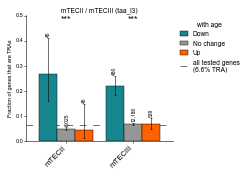

In [13]:
_ = tra.plot_tra_fraction_bars(
    tra_l3, cell_types=FOCUS_L3, stats=sum_l3,
    figsize=tra.calc_figsize(width=60, height=50, margin=0),
    title='mTECII / mTECIII (taa_l3)',
    save=f'{plot_path}/tra_pc_tau0.8_fraction_bars_mTEC23_taa_l3_adult_vs_infant_{today}.pdf')


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_fraction_bars_TECmim_taa_l4_adult_vs_infant_2026-09-15.pdf


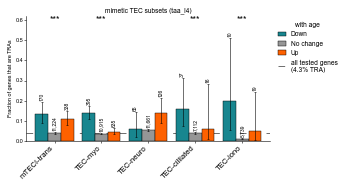

In [14]:
_ = tra.plot_tra_fraction_bars(
    tra_mim, cell_types=FOCUS_MIM, stats=sum_mim,
    title='mimetic TEC subsets (taa_l4)',
    save=f'{plot_path}/tra_pc_tau0.8_fraction_bars_TECmim_taa_l4_adult_vs_infant_{today}.pdf')


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_fraction_bars_mTEC23_TECmim_adult_vs_infant_2026-09-15.pdf


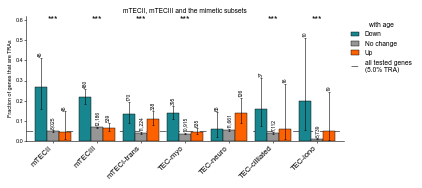

saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_stacked_mTEC23_TECmim_adult_vs_infant_2026-09-15.pdf


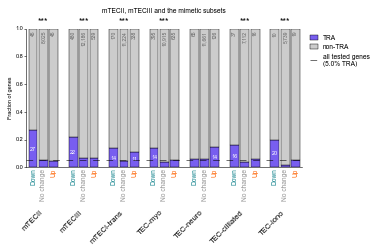

In [15]:
# Both groups on one axis (taa_l4 labels throughout)
sum_all = tra.tra_summary(tra_all, comparison='dw_vs_ns')
_ = tra.plot_tra_fraction_bars(
    tra_all, cell_types=FOCUS_ALL, stats=sum_all,
    title='mTECII, mTECIII and the mimetic subsets',
    save=f'{plot_path}/tra_pc_tau0.8_fraction_bars_mTEC23_TECmim_adult_vs_infant_{today}.pdf')

_ = tra.plot_tra_stacked(
    tra_all, cell_types=FOCUS_ALL, stats=sum_all,
    title='mTECII, mTECIII and the mimetic subsets',
    save=f'{plot_path}/tra_pc_tau0.8_stacked_mTEC23_TECmim_adult_vs_infant_{today}.pdf')


## 3. Fisher exact tests

`dw_vs_ns` asks whether the down-with-age genes hold more TRAs than the genes that do not change;
`up_vs_ns` is the same test on the up-regulated genes, as a direction control. BH-FDR across the
cell types within each comparison.


In [16]:
fisher_l3 = tra.fisher_tra(tra_l3, comparisons=('dw_vs_ns', 'up_vs_ns'))
fisher_l3.round(4)


,cell_type,comparison,n_focal,n_ref,tra_focal,tra_ref,frac_tra_focal,frac_tra_ref,odds_ratio_sample,ci_low,ci_high,pvalue,padj,log2_odds_ratio,stars
0,mTECII,dw_vs_ns,45,8025,12,407,0.2667,0.0507,6.9760,3.6156,13.4596,0.0,0.0,2.8024,***
1,mTECIII,dw_vs_ns,480,12186,106,842,0.2208,0.0691,3.8292,3.0536,4.8019,0.0,0.0,1.9371,***
2,mTECII,up_vs_ns,45,8025,2,407,0.0444,0.0507,1.0745,0.2992,3.8592,1.0,1.0,0.1036,ns
3,mTECIII,up_vs_ns,539,12186,37,842,0.0686,0.0691,1.0049,0.7159,1.4105,1.0,1.0,0.0070,ns


In [17]:
fisher_mim = tra.fisher_tra(tra_mim, comparisons=('dw_vs_ns', 'up_vs_ns'))
fisher_mim.round(4)


,cell_type,comparison,n_focal,n_ref,tra_focal,tra_ref,frac_tra_focal,frac_tra_ref,odds_ratio_sample,ci_low,ci_high,pvalue,padj,log2_odds_ratio,stars
0,mTECI-trans,dw_vs_ns,170,11224,23,479,0.1353,0.0427,3.5704,2.2883,5.5707,0.0000,0.0000,1.8361,***
1,TEC-myo,dw_vs_ns,395,10915,55,423,0.1392,0.0388,4.0383,2.9920,5.4506,0.0000,0.0000,2.0138,***
2,TEC-neuro,dw_vs_ns,65,11661,4,653,0.0615,0.0560,1.2326,0.4718,3.2205,0.7843,0.7843,0.3017,ns
3,TEC-cilliated,dw_vs_ns,37,7112,6,293,0.1622,0.0412,4.7945,2.0443,11.2447,0.0040,0.0066,2.2614,**
4,TEC-iono,dw_vs_ns,10,5739,2,79,0.2000,0.0138,20.9415,5.0243,87.2850,0.0082,0.0102,4.3883,*
5,mTECI-trans,up_vs_ns,338,11224,38,479,0.1124,0.0427,2.8711,2.0278,4.0652,0.0000,0.0000,1.5216,***
6,TEC-myo,up_vs_ns,635,10915,31,423,0.0488,0.0388,1.2910,0.8907,1.8712,0.2067,0.2922,0.3685,ns
7,TEC-neuro,up_vs_ns,126,11661,18,653,0.1429,0.0560,2.8723,1.7434,4.7322,0.0003,0.0007,1.5222,***
8,TEC-cilliated,up_vs_ns,16,7112,1,293,0.0625,0.0412,2.2486,0.4191,12.0654,0.4907,0.4907,1.1690,ns
9,TEC-iono,up_vs_ns,19,5739,1,79,0.0526,0.0138,5.7731,1.0775,30.9326,0.2338,0.2922,2.5293,ns


### With the expression-level control

TRAs are lower-expressed than non-TRAs while significant genes skew high-expressed, so the raw
Fisher odds ratio mixes TRA biology with detection power. `OR_matched` repeats the test stratified
by baseMean decile (Cochran-Mantel-Haenszel), and `permutation_tra` gives an exact-style null for
the small subsets by shuffling the TRA label within those same expression bins.


In [18]:
sum_l3.round(4)


,cell_type,n_focal,n_ref,frac_tra_focal,frac_tra_ref,OR_fisher,OR_fisher_ci,pvalue_fisher,padj_fisher,stars_fisher,obs_tra,exp_tra_matched,OR_matched,OR_matched_ci,pvalue_matched,padj_matched,stars_matched
0,mTECII,45,8025,0.2667,0.0507,6.9760,3.62-13.46,0.0,0.0,***,12,2.1896,7.4088,3.77-14.55,0.0,0.0,***
1,mTECIII,480,12186,0.2208,0.0691,3.8292,3.05-4.80,0.0,0.0,***,106,26.9379,6.2953,4.90-8.09,0.0,0.0,***


In [19]:
sum_mim.round(4)


,cell_type,n_focal,n_ref,frac_tra_focal,frac_tra_ref,OR_fisher,OR_fisher_ci,pvalue_fisher,padj_fisher,stars_fisher,obs_tra,exp_tra_matched,OR_matched,OR_matched_ci,pvalue_matched,padj_matched,stars_matched
0,mTECI-trans,170,11224,0.1353,0.0427,3.5704,2.29-5.57,0.0000,0.0000,***,23,6.0097,4.7913,2.98-7.71,0.0000,0.0000,***
1,TEC-myo,395,10915,0.1392,0.0388,4.0383,2.99-5.45,0.0000,0.0000,***,55,13.4010,5.4695,3.98-7.52,0.0000,0.0000,***
2,TEC-neuro,65,11661,0.0615,0.0560,1.2326,0.47-3.22,0.7843,0.7843,ns,4,2.5616,1.5984,0.58-4.41,0.3534,0.3534,ns
3,TEC-cilliated,37,7112,0.1622,0.0412,4.7945,2.04-11.24,0.0040,0.0066,**,6,1.6356,4.3336,1.78-10.56,0.0004,0.0006,***
4,TEC-iono,10,5739,0.2000,0.0138,20.9415,5.02-87.28,0.0082,0.0102,*,2,0.1481,17.5971,3.59-86.31,0.0000,0.0000,***


In [20]:
perm_l3 = tra.permutation_tra(tra_l3, comparison='dw_vs_ns', n_perm=10000, stratify_on='baseMean')
perm_mim = tra.permutation_tra(tra_mim, comparison='dw_vs_ns', n_perm=10000, stratify_on='baseMean')
pd.concat([perm_l3, perm_mim]).round(4)


,cell_type,comparison,tra_focal,null_mean,null_sd,obs_over_exp,zscore,pvalue,padj,stars
0,mTECII,dw_vs_ns,12,2.1935,1.4468,5.4707,6.7780,0.0001,0.0001,***
1,mTECIII,dw_vs_ns,106,27.1112,4.8359,3.9098,16.3133,0.0001,0.0001,***
0,mTECI-trans,dw_vs_ns,23,5.9195,2.3136,3.8855,7.3827,0.0001,0.0002,***
1,TEC-myo,dw_vs_ns,55,13.1023,3.4449,4.1977,12.1623,0.0001,0.0002,***
2,TEC-neuro,dw_vs_ns,4,2.5824,1.5504,1.5489,0.9144,0.5098,0.5098,ns
3,TEC-cilliated,dw_vs_ns,6,1.6279,1.2328,3.6857,3.5464,0.0075,0.0125,*
4,TEC-iono,dw_vs_ns,2,0.1508,0.3840,13.2626,4.8156,0.0183,0.0229,*


## 4. Tissue of origin of the TRAs lost with age

Dot area is the number of down-regulated TRAs assigned to that GTEx tissue, dot colour is the share
of the population's down TRAs. Using area rather than a 100%-stacked bar keeps the sparse subsets
honest: a population with two down TRAs should not look like a strong tissue preference.


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_tissue_dotplot_mTEC23_taa_l3_adult_vs_infant_2026-09-15.pdf


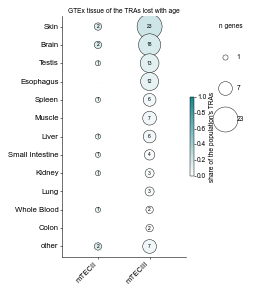

In [21]:
_ = tra.plot_tissue_dotplot(
    tra_l3, cell_types=FOCUS_L3, change='sign_dw', n_tissues=12,
    title='GTEx tissue of the TRAs lost with age',
    save=f'{plot_path}/tra_pc_tau0.8_tissue_dotplot_mTEC23_taa_l3_adult_vs_infant_{today}.pdf')


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_tissue_dotplot_TECmim_taa_l4_adult_vs_infant_2026-09-15.pdf


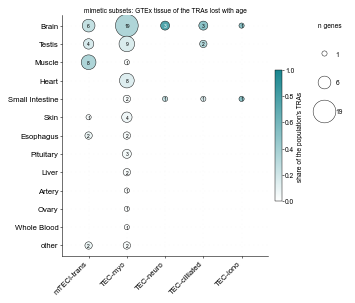

In [22]:
_ = tra.plot_tissue_dotplot(
    tra_mim, cell_types=FOCUS_MIM, change='sign_dw', n_tissues=12,
    title='mimetic subsets: GTEx tissue of the TRAs lost with age',
    save=f'{plot_path}/tra_pc_tau0.8_tissue_dotplot_TECmim_taa_l4_adult_vs_infant_{today}.pdf')


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_tissue_dotplot_mTEC23_TECmim_adult_vs_infant_2026-09-15.pdf


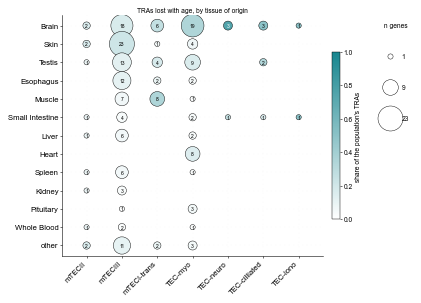

In [23]:
_ = tra.plot_tissue_dotplot(
    tra_all, cell_types=FOCUS_ALL, change='sign_dw', n_tissues=12,
    title='TRAs lost with age, by tissue of origin',
    save=f'{plot_path}/tra_pc_tau0.8_tissue_dotplot_mTEC23_TECmim_adult_vs_infant_{today}.pdf')


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_tissue_composition_mTEC23_TECmim_adult_vs_infant_2026-09-15.pdf


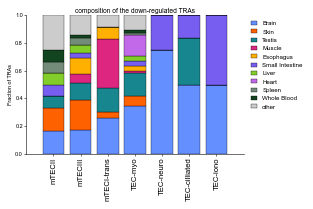

In [24]:
# The proportional view as well, for the populations that carry enough genes to support it
_ = tra.plot_tra_tissue_composition(
    tra_all, cell_types=FOCUS_ALL, change='sign_dw', n_tissues=10,
    title='composition of the down-regulated TRAs',
    save=f'{plot_path}/tra_pc_tau0.8_tissue_composition_mTEC23_TECmim_adult_vs_infant_{today}.pdf')


### The genes themselves

Each down-regulated TRA at its log2 fold change, coloured by tissue of origin. Panels are capped at
the 20 largest absolute fold changes; the title gives the total.


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_down_genes_mTEC23_taa_l3_adult_vs_infant_2026-09-15.pdf


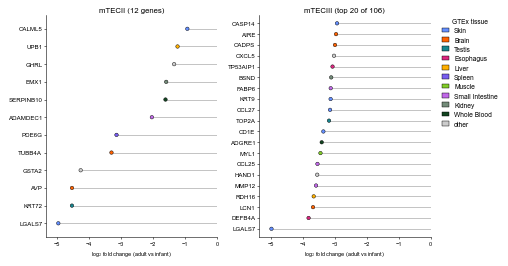

In [25]:
_ = tra.plot_tra_lollipop(
    tra_l3, cell_types=FOCUS_L3, top_n=20, ncols=2,
    save=f'{plot_path}/tra_pc_tau0.8_down_genes_mTEC23_taa_l3_adult_vs_infant_{today}.pdf')


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_down_genes_TECmim_taa_l4_adult_vs_infant_2026-09-15.pdf


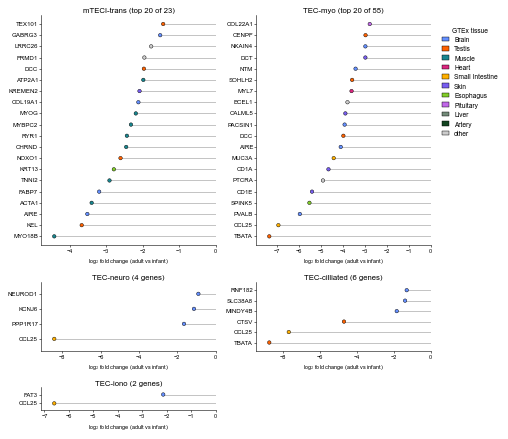

In [26]:
_ = tra.plot_tra_lollipop(
    tra_mim, cell_types=FOCUS_MIM, top_n=20, ncols=2,
    save=f'{plot_path}/tra_pc_tau0.8_down_genes_TECmim_taa_l4_adult_vs_infant_{today}.pdf')


### The TRAs that go UP with age

The same plot for the up-regulated side, largest fold change at the bottom of each panel. Check the
`up_vs_ns` rows of the Fisher tables above before reading these as a set: in `04c`/`04d` the
up-regulated genes carried TRAs at background frequency in every population except TEC-mim, which
gets its own panel below.


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_up_genes_mTEC23_taa_l3_adult_vs_infant_2026-09-15.pdf


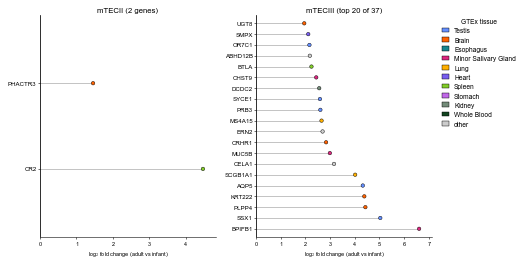

In [27]:
_ = tra.plot_tra_lollipop(
    tra_l3, cell_types=FOCUS_L3, change='sign_up', top_n=20, ncols=2,
    save=f'{plot_path}/tra_pc_tau0.8_up_genes_mTEC23_taa_l3_adult_vs_infant_{today}.pdf')


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_up_genes_TECmim_taa_l4_adult_vs_infant_2026-09-15.pdf


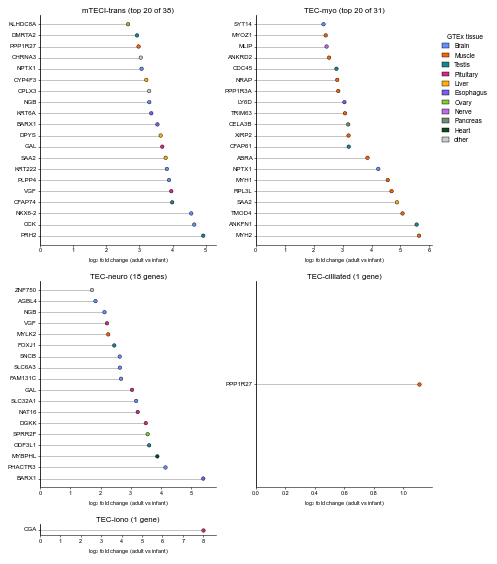

In [28]:
_ = tra.plot_tra_lollipop(
    tra_mim, cell_types=FOCUS_MIM, change='sign_up', top_n=20, ncols=2,
    save=f'{plot_path}/tra_pc_tau0.8_up_genes_TECmim_taa_l4_adult_vs_infant_{today}.pdf')


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/plots/tra/tra_pc_tau0.8_up_genes_TECmim_taa_l3_adult_vs_infant_2026-09-15.pdf


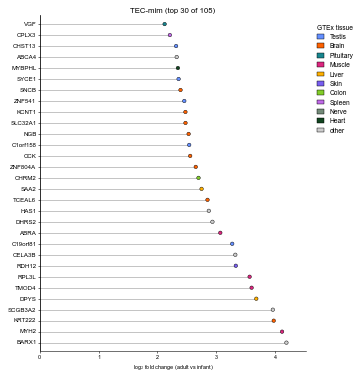

In [29]:
# TEC-mim (taa_l3) was the one population with TRAs over-represented among the up-regulated genes
# in 04c/04d, so its risers get their own panel here too.
tra_mim_l3 = tra.build_tra_table(de_l3, gtex=gtex, cell_types=['TEC-mim'],
                                 gene_universe=pc_genes, tau=TAU, verbose=False)
_ = tra.plot_tra_lollipop(
    tra_mim_l3, cell_types=['TEC-mim'], change='sign_up', top_n=30, ncols=1, panel_width=70,
    save=f'{plot_path}/tra_pc_tau0.8_up_genes_TECmim_taa_l3_adult_vs_infant_{today}.pdf')


## Save the tables


In [30]:
dw_l3 = tra.down_tra_genes(tra_l3, cell_types=FOCUS_L3)
dw_mim = tra.down_tra_genes(tra_mim, cell_types=FOCUS_MIM)
up_l3 = tra.down_tra_genes(tra_l3, cell_types=FOCUS_L3, change='sign_up')
up_mim = tra.down_tra_genes(tra_mim, cell_types=FOCUS_MIM, change='sign_up')
up_mim_l3 = tra.down_tra_genes(tra_mim_l3, cell_types=['TEC-mim'], change='sign_up')

tables = {
    'focus_fisher_mTEC23_taa_l3': fisher_l3,
    'focus_summary_mTEC23_taa_l3': sum_l3,
    'focus_perm_mTEC23_taa_l3': perm_l3,
    'focus_fisher_TECmim_taa_l4': fisher_mim,
    'focus_summary_TECmim_taa_l4': sum_mim,
    'focus_perm_TECmim_taa_l4': perm_mim,
    'focus_summary_mTEC23_TECmim': sum_all,
    'focus_down_TRA_genes_mTEC23_taa_l3': dw_l3,
    'focus_down_TRA_genes_TECmim_taa_l4': dw_mim,
    'focus_up_TRA_genes_mTEC23_taa_l3': up_l3,
    'focus_up_TRA_genes_TECmim_taa_l4': up_mim,
    'focus_up_TRA_genes_TECmim_taa_l3': up_mim_l3,
}
for name, t in tables.items():
    p = f'{results_path}/tra_pc_tau0.8_{name}_adult_vs_infant_{today}.csv'
    t.to_csv(p, index=False)
    print(f'{str(t.shape):12s} {p}')


(4, 15)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_fisher_mTEC23_taa_l3_adult_vs_infant_2026-09-15.csv
(2, 17)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_summary_mTEC23_taa_l3_adult_vs_infant_2026-09-15.csv
(2, 10)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_perm_mTEC23_taa_l3_adult_vs_infant_2026-09-15.csv
(10, 15)     /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_fisher_TECmim_taa_l4_adult_vs_infant_2026-09-15.csv
(5, 17)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_summary_TECmim_taa_l4_adult_vs_infant_2026-09-15.csv


(5, 10)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_perm_TECmim_taa_l4_adult_vs_infant_2026-09-15.csv
(7, 17)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_summary_mTEC23_TECmim_adult_vs_infant_2026-09-15.csv
(118, 8)     /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_down_TRA_genes_mTEC23_taa_l3_adult_vs_infant_2026-09-15.csv
(90, 8)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_down_TRA_genes_TECmim_taa_l4_adult_vs_infant_2026-09-15.csv
(39, 8)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_up_TRA_genes_mTEC23_taa_l3_adult_vs_infant_2026-09-15.csv
(89, 8)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_focus_up_TRA_genes_TECmim_taa_l4_adult_vs_infant_2026-09-15.csv
(105, 8)     /nfs/t

In [31]:
# The filter diagnostics from section 0
for name, t in {'filter_comparison_dw_vs_ns': comparison,
                'filter_removed_significant_TRAs': removed_tab,
                'filter_biotypes_of_unfiltered_TRA_calls': biotype_tab.reset_index()}.items():
    p = f'{results_path}/tra_pc_tau0.8_{name}_adult_vs_infant_{today}.csv'
    t.to_csv(p, index=False)
    print(f'{str(t.shape):12s} {p}')


(7, 13)      /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_filter_comparison_dw_vs_ns_adult_vs_infant_2026-09-15.csv
(7, 4)       /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_filter_removed_significant_TRAs_adult_vs_infant_2026-09-15.csv
(7, 4)       /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/tra_pc_tau0.8_filter_biotypes_of_unfiltered_TRA_calls_adult_vs_infant_2026-09-15.csv


In [32]:
# The down-regulated TRAs, grouped by tissue, for the focus populations
(dw_l3.groupby(['cell_type', 'top1_tissue'], observed=True)['gene_name']
      .apply(lambda s: ', '.join(sorted(s)))
      .reset_index()
      .rename(columns={'gene_name': 'genes'}))


,cell_type,top1_tissue,genes
0,mTECII,Brain,"AVP, TUBB4A"
1,mTECII,Kidney,EMX1
2,mTECII,Liver,UPB1
3,mTECII,Pancreas,GSTA2
4,mTECII,Skin,"CALML5, LGALS7"
5,mTECII,Small Intestine,ADAMDEC1
6,mTECII,Spleen,PDE6G
7,mTECII,Stomach,GHRL
8,mTECII,Testis,KRT72
9,mTECII,Whole Blood,SERPINB10


In [33]:
(dw_mim.groupby(['cell_type', 'top1_tissue'], observed=True)['gene_name']
       .apply(lambda s: ', '.join(sorted(s)))
       .reset_index()
       .rename(columns={'gene_name': 'genes'}))


,cell_type,top1_tissue,genes
0,mTECI-trans,Brain,"AIRE, CNTNAP2, COL19A1, FABP7, GABRA5, GABRG3"
1,mTECI-trans,Esophagus,"ESPL1, KRT13"
2,mTECI-trans,Minor Salivary Gland,LRRC26
3,mTECI-trans,Muscle,"ACTA1, ATP2A1, CHRND, MYBPC2, MYO18B, MYOG, RY..."
4,mTECI-trans,Nerve,FRMD1
5,mTECI-trans,Skin,KREMEN2
6,mTECI-trans,Testis,"DCC, KEL, NOXO1, TEX101"
7,TEC-myo,Adrenal Gland,ASB4
8,TEC-myo,Artery,ST6GAL2
9,TEC-myo,Brain,"AIRE, ARPP21, CDH7, DCX, GABRA5, GPR37, KCNJ6,..."


## Supplementary table: TRAs in mTECII and the mimetic TEC subsets

One workbook for the manuscript:

* **README** - what the table is, how every quantity was defined, and a legend for every column.
* **Summary** - per population: genes and TRAs tested, down / no change / up counts and TRA fractions,
  and the enrichment tests (Fisher, expression-matched, permutation). FDRs are recomputed across the
  six populations in this table, so they differ slightly from the panels above.
* **All TRAs** - every TRA significantly changed with age (adjusted P < 0.05) in these populations.
* **One sheet per population** with the same columns.

Populations: mTECII and the taa_l4 children of `TEC-mim` that were tested (TEC-tuft was not). All
from the taa_l4 DE table; mTECII is identical at taa_l3 and taa_l4 (asserted above). The AIRE / FEZF2
columns annotate each TRA with the mouse regulator sets used in `04e`.


In [34]:
FOCUS_SUPP = ['mTECII'] + FOCUS_MIM
supp_dir = os.path.join(results_path, 'supplementary')
os.makedirs(supp_dir, exist_ok=True)

aire_set, aire_bg = tra.load_regulator_set('AIRE')
fezf2_set, fezf2_bg = tra.load_regulator_set('FEZF2')

supp_genes, supp_legend = tra.supplementary_tra_table(
    tra_all, cell_types=FOCUS_SUPP, biotypes=biotypes,
    regulator_sets={'AIRE': (aire_set, aire_bg), 'FEZF2': (fezf2_set, fezf2_bg)},
    contrast_label='adult vs infant')
assert (supp_genes['Gene biotype'] == 'protein_coding').all(), 'non-coding gene in the table'

supp_summary = tra.supplementary_summary_table(tra_all, cell_types=FOCUS_SUPP, n_perm=10000)

print(supp_genes.groupby(['Cell type', 'Direction with age'], sort=False).size().to_string())
supp_summary.round(4)


AIRE: 2,847 target genes, 14,422 in the assayed background
  source: Sansom et al. 2014 Genome Res, Aire+ vs Aire-KO mTEC (>2 fold, 5% FDR)
FEZF2: 197 target genes, 14,733 in the assayed background
  source: Takaba et al. 2015 Cell, re-derived from GSE69105 (FC>2, p<0.05)


Cell type      Direction with age
mTECII         Down with age         12
               Up with age            2
mTECI-trans    Down with age         23
               Up with age           38
TEC-myo        Down with age         55
               Up with age           31
TEC-neuro      Down with age          4
               Up with age           18
TEC-cilliated  Down with age          6
               Up with age            1
TEC-iono       Down with age          2
               Up with age            1


,Cell type,Genes tested,TRAs tested,"TRA fraction, all tested genes (%)",Down with age: genes,Down with age: TRAs,Down with age: TRA fraction (%),No change: genes,No change: TRAs,No change: TRA fraction (%),Up with age: genes,Up with age: TRAs,Up with age: TRA fraction (%),Down vs no change: odds ratio (Fisher),Down vs no change: 95% CI,Down vs no change: P value (Fisher),Down vs no change: FDR (Fisher),Down vs no change: odds ratio (expression-matched),Down vs no change: FDR (expression-matched),"Down vs no change: P value (permutation, expression-matched)",Up vs no change: odds ratio (Fisher),Up vs no change: 95% CI,Up vs no change: P value (Fisher),Up vs no change: FDR (Fisher)
0,mTECII,8115,421,5.1879,45,12,26.6667,8025,407,5.0717,45,2,4.4444,6.9760,3.62-13.46,0.0000,0.0000,7.4088,0.0000,0.0001,1.0745,0.30-3.86,1.0000,1.0000
1,mTECI-trans,11732,540,4.6028,170,23,13.5294,11224,479,4.2676,338,38,11.2426,3.5704,2.29-5.57,0.0000,0.0000,4.7913,0.0000,0.0001,2.8711,2.03-4.07,0.0000,0.0000
2,TEC-myo,11945,509,4.2612,395,55,13.9241,10915,423,3.8754,635,31,4.8819,4.0383,2.99-5.45,0.0000,0.0000,5.4695,0.0000,0.0001,1.2910,0.89-1.87,0.2067,0.3506
3,TEC-neuro,11852,675,5.6952,65,4,6.1538,11661,653,5.5999,126,18,14.2857,1.2326,0.47-3.22,0.7843,0.7843,1.5984,0.3534,0.5086,2.8723,1.74-4.73,0.0003,0.0008
4,TEC-cilliated,7165,300,4.1870,37,6,16.2162,7112,293,4.1198,16,1,6.2500,4.7945,2.04-11.24,0.0040,0.0059,4.3336,0.0005,0.0111,2.2486,0.42-12.07,0.4907,0.5888
5,TEC-iono,5768,82,1.4216,10,2,20.0000,5739,79,1.3765,19,1,5.2632,20.9415,5.02-87.28,0.0082,0.0098,17.5971,0.0000,0.0193,5.7731,1.08-30.93,0.2338,0.3506


In [35]:
n_gtex_tissues = len(pd.read_csv(f'{general_data_path}/tra_analysis/GTEX_log1p_TPM_by_broad_tissue.csv',
                                 nrows=0).columns) - 1
annot_src = '; '.join(f'{k}: {v:,} atlas genes' for k, v in biotypes['annotation_source'].value_counts().items())

readme = pd.DataFrame([
    ('Title', 'Tissue-restricted antigens (TRAs) differentially expressed with age in mTECII and '
              'mimetic thymic epithelial cell subsets (protein-coding genes).'),
    ('Sheets', 'Summary: per-population gene and TRA counts and enrichment tests. All TRAs: every TRA '
               'significantly changed with age in the listed populations. One further sheet per '
               'population with the same columns as All TRAs.'),
    ('Populations', ', '.join(FOCUS_SUPP) + '. The mimetic subsets are the annotation level taa_l4 '
                    'children of TEC-mim in the curated annotation (this includes mTECI-trans); '
                    'TEC-tuft is annotated but was not tested for differential expression.'),
    ('Differential expression', 'DESeq2 age-effect results, adult vs infant, at annotation level '
                                'taa_l4 (thyAgeing_dea_taa_l4_adult_vs_infant_ageEffect.pkl). '
                                'Significant: adjusted P < 0.05; direction from the sign of the '
                                'log2 fold change.'),
    ('Gene universe', 'Per population: genes tested by DESeq2 (non-missing adjusted P) that are '
                      'protein-coding (GENCODE gene_type of the atlas Ensembl gene record; '
                      f'{annot_src}) and reach >= 1 TPM in their highest-expressing GTEx broad tissue.'),
    ('TRA definition', f'GTEx tissue specificity index tau >= {TAU} across '
                       f'{n_gtex_tissues} GTEx broad tissues, within the gene universe.'),
    ('Enrichment tests (Summary)', 'Fisher: two-sided Fisher exact test of TRA vs non-TRA among genes '
                                   'down (or up) with age versus genes not changing; odds ratio with '
                                   'Haldane-corrected Woolf 95% CI. Expression-matched: '
                                   'Cochran-Mantel-Haenszel test stratified by baseMean decile within '
                                   'each population (left blank when fewer than 10 genes change). '
                                   'Permutation: TRA labels shuffled 10,000 times within baseMean '
                                   'deciles, two-sided empirical P. FDR: Benjamini-Hochberg across '
                                   'the populations in this table.'),
    ('Generated', f'{today}; TEC_compartment/notebooks/notebooks_revisions/'
                  '04f_TRA_mTEC_mimetic_proteincoding_tau0.8_VK.ipynb'),
    ('', ''),
    ('COLUMN LEGEND (TRA sheets)', ''),
], columns=['Item', 'Description'])
readme = pd.concat([readme, supp_legend.rename(columns={'Column': 'Item'})], ignore_index=True)

sheets = {'Summary': supp_summary, 'All TRAs': supp_genes}
for ct in FOCUS_SUPP:
    sheets[ct] = supp_genes[supp_genes['Cell type'] == ct]

xlsx_path = f'{supp_dir}/Supplementary_Table_TRAs_mTECII_mimeticTEC_proteincoding_tau0.8_{today}.xlsx'
tra.write_supplementary_xlsx(xlsx_path, sheets, readme=readme)
supp_genes.to_csv(xlsx_path.replace('.xlsx', '_AllTRAs.csv'), index=False)
supp_summary.to_csv(xlsx_path.replace('.xlsx', '_Summary.csv'), index=False)
readme


wrote /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/supplementary/Supplementary_Table_TRAs_mTECII_mimeticTEC_proteincoding_tau0.8_2026-09-15.xlsx: Summary (6 rows), All TRAs (193 rows), mTECII (14 rows), mTECI-trans (61 rows), TEC-myo (86 rows), TEC-neuro (22 rows), TEC-cilliated (7 rows), TEC-iono (3 rows)


'/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/tra/supplementary/Supplementary_Table_TRAs_mTECII_mimeticTEC_proteincoding_tau0.8_2026-09-15.xlsx'

,Item,Description
0,Title,Tissue-restricted antigens (TRAs) differential...
1,Sheets,Summary: per-population gene and TRA counts an...
2,Populations,"mTECII, mTECI-trans, TEC-myo, TEC-neuro, TEC-c..."
3,Differential expression,"DESeq2 age-effect results, adult vs infant, at..."
4,Gene universe,Per population: genes tested by DESeq2 (non-mi...
5,TRA definition,GTEx tissue specificity index tau >= 0.8 acros...
6,Enrichment tests (Summary),Fisher: two-sided Fisher exact test of TRA vs ...
7,Generated,2026-09-15; TEC_compartment/notebooks/notebook...
8,,
9,COLUMN LEGEND (TRA sheets),


In [36]:
# Read the workbook back as a check of what a reader will see
xl = pd.ExcelFile(xlsx_path)
print(xl.sheet_names)
back = pd.read_excel(xlsx_path, sheet_name='All TRAs')
assert len(back) == len(supp_genes) and list(back.columns) == list(supp_genes.columns)
back.head(15)


['README', 'Summary', 'All TRAs', 'mTECII', 'mTECI-trans', 'TEC-myo', 'TEC-neuro', 'TEC-cilliated', 'TEC-iono']


,Cell type,Gene symbol,Ensembl gene ID,Gene biotype,Direction with age,log2 fold change (adult vs infant),log2 fold change SE,Wald statistic,P value,Adjusted P value (BH),baseMean,GTEx tissue specificity (tau),GTEx maximum expression (TPM),GTEx top tissue,GTEx top 5 tissues,AIRE-dependent in mouse,FEZF2-dependent in mouse
0,mTECII,LGALS7,ENSG00000205076,protein_coding,Down with age,-4.963397,1.375924,-3.607320,3.093758e-04,0.040928,67.342079,0.937864,281.68900,Skin,Skin; Esophagus; Vagina; Minor Salivary Gland;...,not assayed,not assayed
1,mTECII,KRT72,ENSG00000170486,protein_coding,Down with age,-4.538258,1.284446,-3.533242,4.104961e-04,0.043898,10.628198,0.918185,53.31730,Testis,Testis; Skin; Whole Blood; Spleen; Small Intes...,not assayed,no
2,mTECII,AVP,ENSG00000101200,protein_coding,Down with age,-4.536806,1.293548,-3.507258,4.527492e-04,0.044413,51.463567,0.979580,378.91200,Brain,Brain; Testis; Kidney; Adipose; Adrenal Gland,yes,no
3,mTECII,GSTA2,ENSG00000244067,protein_coding,Down with age,-4.265693,1.171575,-3.640991,2.715910e-04,0.038649,8.251209,0.857588,110.89600,Pancreas,Pancreas; Liver; Testis; Kidney; Small Intestine,not assayed,not assayed
4,mTECII,TUBB4A,ENSG00000104833,protein_coding,Down with age,-3.305298,0.805719,-4.102294,4.090735e-05,0.016094,16.328271,0.849282,988.75400,Brain,Brain; Adrenal Gland; Testis; Nerve; Spleen,yes,no
5,mTECII,PDE6G,ENSG00000185527,protein_coding,Down with age,-3.148013,0.759442,-4.145164,3.395701e-05,0.016094,8.804029,0.827722,8.52651,Spleen,Spleen; Whole Blood; Testis; Kidney; Small Int...,no,no
6,mTECII,ADAMDEC1,ENSG00000134028,protein_coding,Down with age,-2.045213,0.543114,-3.765713,1.660747e-04,0.032668,11.337454,0.919850,198.60500,Small Intestine,Small Intestine; Colon; Spleen; Adipose; Stomach,yes,no
7,mTECII,SERPINB10,ENSG00000242550,protein_coding,Down with age,-1.620378,0.397610,-4.075293,4.595644e-05,0.017182,18.537580,0.950975,2.72649,Whole Blood,Whole Blood; Skin; Spleen; Esophagus; Adipose,not assayed,not assayed
8,mTECII,EMX1,ENSG00000135638,protein_coding,Down with age,-1.598586,0.454998,-3.513393,4.424220e-04,0.044413,19.921461,0.936735,18.79510,Kidney,Kidney; Brain; Testis; Colon; Pituitary,yes,no
9,mTECII,GHRL,ENSG00000157017,protein_coding,Down with age,-1.350723,0.360137,-3.750580,1.764261e-04,0.032668,22.851424,0.855971,143.51500,Stomach,Stomach; Spleen; Thyroid; Nerve; Whole Blood,yes,no
